MD# 01 · Data Cleaning & Exploratory Data Analysis
**Goal:** understand which customers leave (churn) a telecom company, before building a prediction model.

**Dataset:** IBM Telco Customer Churn — 7,043 customers, 21 columns (demographics, services, contract, billing, churn label).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu
pd.set_option('display.max_columns', 30)
STAY, CHURN = '#2a78d6', '#eb6834'
sns.set_theme(style='whitegrid', font_scale=1.0)
df = pd.read_csv('../data/raw/Telco-Customer-Churn.csv')
df.shape

(7043, 21)

In [2]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

MD## 1. Data cleaning

In [4]:
# TotalCharges is stored as text; blank strings appear for brand-new customers
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')
print('Missing TotalCharges:', df['TotalCharges'].isna().sum())
print('Of those, tenure == 0:', (df.loc[df['TotalCharges'].isna(), 'tenure'] == 0).sum())

Missing TotalCharges: 11
Of those, tenure == 0: 11


MD All 11 missing values belong to customers with **tenure = 0** (they joined this month and haven't been billed yet), so the correct value is **0**, not the mean.

In [5]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
df['Churn'] = (df['Churn'] == 'Yes').astype(int)
print('Duplicate customer IDs:', df['customerID'].duplicated().sum())
print('Missing values left:', df.isna().sum().sum())

Duplicate customer IDs: 0
Missing values left: 0


In [6]:
df.to_csv('../data/processed/churn_clean.csv', index=False)
df.describe()

,tenure,MonthlyCharges,TotalCharges,Churn
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304,0.265370
std,24.559481,30.090047,2266.794470,0.441561
min,0.000000,18.250000,0.000000,0.000000
25%,9.000000,35.500000,398.550000,0.000000
50%,29.000000,70.350000,1394.550000,0.000000
75%,55.000000,89.850000,3786.600000,1.000000
max,72.000000,118.750000,8684.800000,1.000000


MD## 2. Target: how many customers churn?

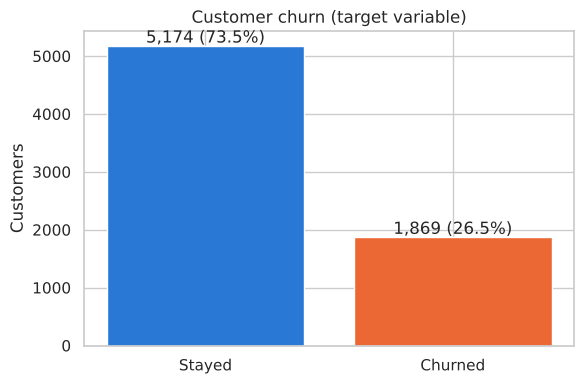

Churn rate: 26.5%


In [7]:
rate = df['Churn'].mean()
counts = df['Churn'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['Stayed', 'Churned'], counts.values, color=[STAY, CHURN])
for i, v in enumerate(counts.values): ax.text(i, v + 60, f'{v:,} ({v/len(df):.1%})', ha='center')
ax.set_title('Customer churn (target variable)'); ax.set_ylabel('Customers')
plt.tight_layout(); plt.savefig('../images/01_churn_distribution.png', dpi=150); plt.show()
print(f'Churn rate: {rate:.1%}')

MD **26.5% churn** → the classes are imbalanced (roughly 3:1). Accuracy alone would be misleading, so the model will be judged on **ROC-AUC, recall and F1**, and trained with class weights.

MD## 3. Churn by customer attributes

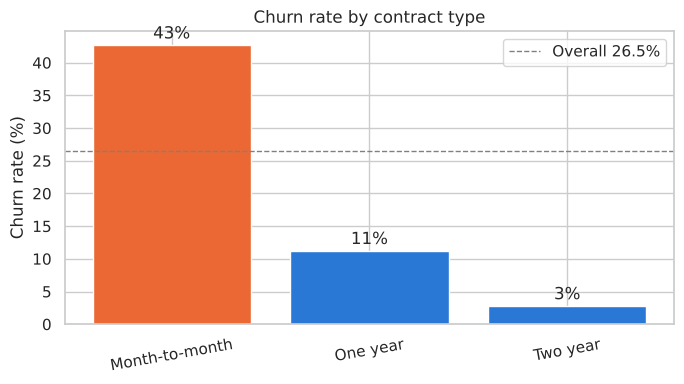

Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn, dtype: float64

In [8]:
def churn_bar(col, fname, title, order=None):
    r = df.groupby(col)['Churn'].mean().reindex(order) if order else df.groupby(col)['Churn'].mean().sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(r.index.astype(str), r.values * 100, color=[CHURN if v > rate else STAY for v in r.values])
    ax.axhline(rate * 100, color='grey', ls='--', lw=1, label=f'Overall {rate:.1%}')
    for i, v in enumerate(r.values): ax.text(i, v * 100 + 1, f'{v:.0%}', ha='center')
    ax.set_ylabel('Churn rate (%)'); ax.set_title(title); ax.legend()
    plt.xticks(rotation=10); plt.tight_layout(); plt.savefig(f'../images/{fname}', dpi=150); plt.show()
    return r

churn_bar('Contract', '02_churn_by_contract.png', 'Churn rate by contract type', ['Month-to-month', 'One year', 'Two year'])

MD **Month-to-month customers churn at 43%**, versus 11% on one-year and 3% on two-year contracts — contract type is the strongest single signal.

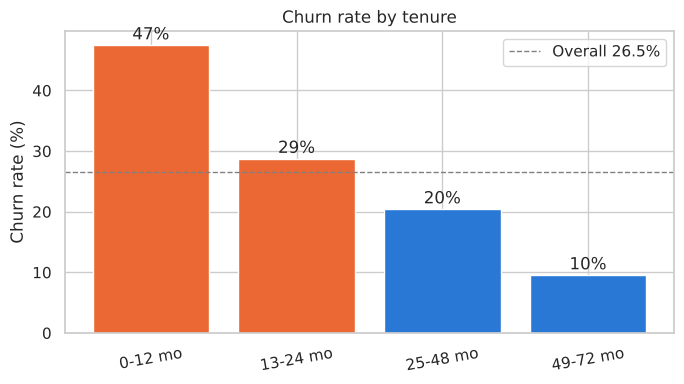

TenureGroup
0-12 mo     0.474382
13-24 mo    0.287109
25-48 mo    0.203890
49-72 mo    0.095132
Name: Churn, dtype: float64

In [9]:
df['TenureGroup'] = pd.cut(df['tenure'], [-1, 12, 24, 48, 72], labels=['0-12 mo', '13-24 mo', '25-48 mo', '49-72 mo'])
churn_bar('TenureGroup', '03_churn_by_tenure.png', 'Churn rate by tenure', ['0-12 mo', '13-24 mo', '25-48 mo', '49-72 mo'])

MD Nearly **half (47%) of customers in their first year churn**, falling to 10% after four years. Early-life customers are the retention priority.

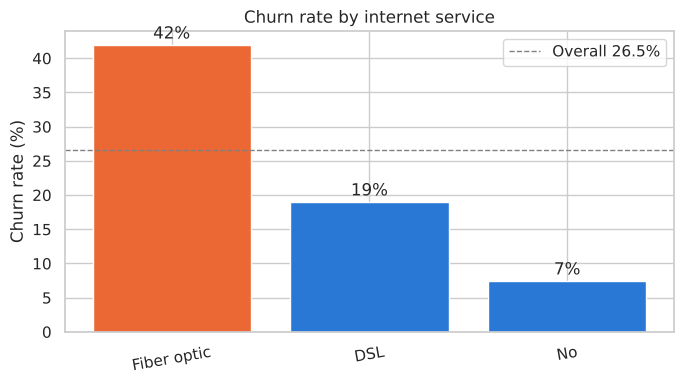

InternetService
Fiber optic    0.418928
DSL            0.189591
No             0.074050
Name: Churn, dtype: float64

In [10]:
churn_bar('InternetService', '04_churn_by_internet.png', 'Churn rate by internet service')

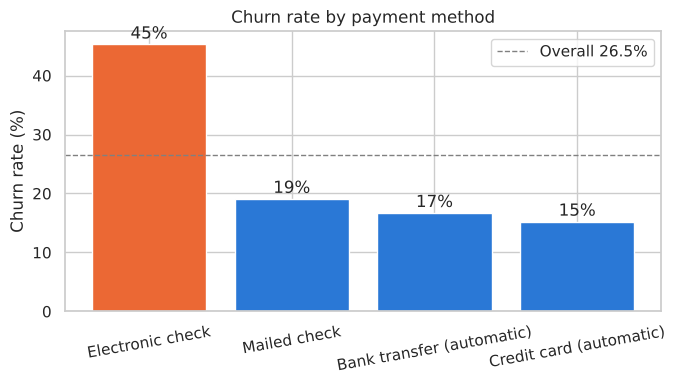

PaymentMethod
Electronic check             0.452854
Mailed check                 0.191067
Bank transfer (automatic)    0.167098
Credit card (automatic)      0.152431
Name: Churn, dtype: float64

In [11]:
churn_bar('PaymentMethod', '05_churn_by_payment.png', 'Churn rate by payment method')

MD **Fiber optic (42%)** and **electronic check (45%)** customers churn far above average; automatic payment customers churn the least (15–17%).

MD## 4. Numeric features

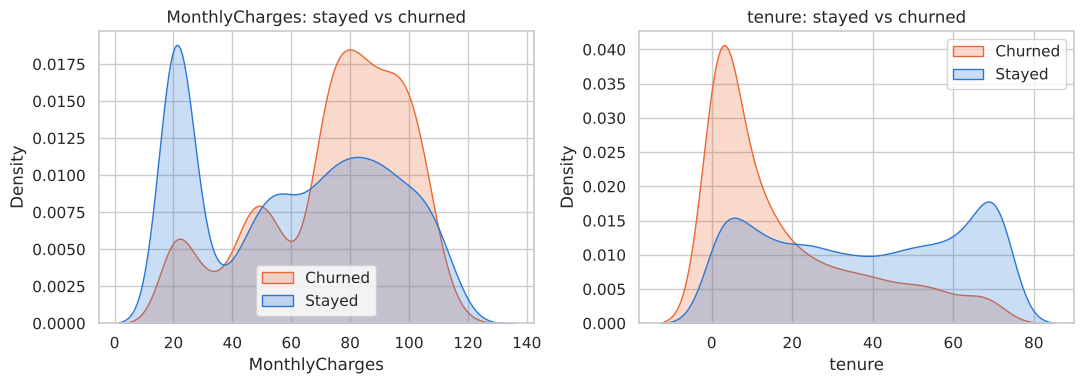

       MonthlyCharges  tenure
Churn                        
0              64.425    38.0
1              79.650    10.0


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ['MonthlyCharges', 'tenure']):
    sns.kdeplot(data=df, x=col, hue='Churn', fill=True, common_norm=False, palette=[STAY, CHURN], ax=ax)
    ax.set_title(f'{col}: stayed vs churned'); ax.legend(['Churned', 'Stayed'])
plt.tight_layout(); plt.savefig('../images/06_numeric_distributions.png', dpi=150); plt.show()
print(df.groupby('Churn')[['MonthlyCharges', 'tenure']].median())

MD## 5. Statistical tests
Are these differences real or random? **Chi-square** for categorical features and **Mann-Whitney U** for numeric ones (non-normal distributions).

In [13]:
cats = ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport', 'OnlineSecurity', 'PaperlessBilling',
        'SeniorCitizen', 'Partner', 'Dependents', 'gender', 'PhoneService']
rows = []
for c in cats:
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(df[c], df['Churn']))
    n = len(df); k = min(pd.crosstab(df[c], df['Churn']).shape) - 1
    rows.append({'feature': c, 'chi2': round(chi2, 1), 'p_value': p, 'cramers_v': round(np.sqrt(chi2 / (n * k)), 3)})
tests = pd.DataFrame(rows).sort_values('cramers_v', ascending=False)
tests['significant (p<0.05)'] = tests['p_value'] < 0.05
tests

,feature,chi2,p_value,cramers_v,significant (p<0.05)
0,Contract,1184.6,5.863038e-258,0.410,True
4,OnlineSecurity,850.0,2.661150e-185,0.347,True
3,TechSupport,828.2,1.443084e-180,0.343,True
1,InternetService,732.3,9.571788e-160,0.322,True
2,PaymentMethod,648.1,3.682355e-140,0.303,True
5,PaperlessBilling,258.3,4.073355e-58,0.191,True
8,Dependents,189.1,4.924922e-43,0.164,True
6,SeniorCitizen,159.4,1.510067e-36,0.150,True
7,Partner,158.7,2.139911e-36,0.150,True
10,PhoneService,0.9,3.387825e-01,0.011,False


In [14]:
for col in ['MonthlyCharges', 'tenure']:
    u, p = mannwhitneyu(df.loc[df.Churn == 1, col], df.loc[df.Churn == 0, col])
    print(f'{col:15s} Mann-Whitney U p-value = {p:.2e}')

MonthlyCharges  Mann-Whitney U p-value = 3.31e-54
tenure          Mann-Whitney U p-value = 2.42e-208


MD Contract, tenure, internet service, payment method, tech support and online security are all significant (p < 0.001). **Gender** and **phone service** are *not* significant (p > 0.05) — they carry little information about churn.

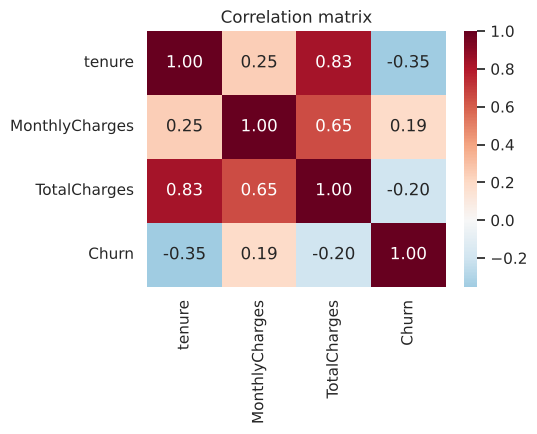

In [15]:
num = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title('Correlation matrix'); plt.tight_layout(); plt.savefig('../images/07_correlation.png', dpi=150); plt.show()

MD `tenure` and `TotalCharges` are strongly correlated (0.83) — expected, since TotalCharges ≈ tenure × MonthlyCharges. Tree models handle this fine; for logistic regression it's worth noting.

## Key EDA findings
1. **26.5%** of customers churn (imbalanced target).
2. **Month-to-month** contracts churn at **43%** vs **3%** for two-year contracts.
3. **47%** of first-year customers churn; long-tenure customers rarely leave.
4. **Fiber optic** and **electronic check** customers are high-risk groups.
5. Gender and phone service show **no significant** relationship with churn.